# Lecture 17: Research with AI, the audit

Redraws the two figures of the lecture from the audit table and recomputes every count quoted in §1 and §6. One row of `results/audit.csv` per error that reached a result, a figure or the text in Lectures 1-16, with its source (a plan-file entry, a commit or the session record).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / 'trading_models').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / 'lectures/17-research-with-ai/scripts'))
import pandas as pd
import l17_audit as A
df = pd.read_csv(ROOT / 'lectures/17-research-with-ai/results/audit.csv')
df[['id', 'lecture', 'error', 'type', 'found_by', 'stage', 'cost']]

,id,lecture,error,type,found_by,stage,cost
0,A,2,KAMA's memory described as rolling only and it...,claim,not recorded,not recorded,text
1,B,4,Filter stable from bar 120 (correct: 121),claim,hand check,after merging,text
2,C,11,Effective number of bets near 1 for three unre...,method,hand check,after results (before merging),table and text
3,D,12,Signals and profits on total returns: levered ...,method,not recorded,before the result,in-sample tables redone
4,E,12,Brief misread: 'robust across all' run as acro...,method,user review,after results (before merging),rule and tests rerun
5,F,12,Positions sized on 36-day volatility: quiet ca...,method,user review,after results (before merging),all streams and tests rerun
6,G,13,Leverage in 2023 credited to the correlation o...,claim,user review,after results (before merging),text
7,H,13-15,VUSTX missing from a saved file: the download ...,data,later reuse of the data,after merging,three lectures rerun
8,I,14,Expectation E1 stated as holding on both datas...,claim,redrawing a figure,after results (before merging),text
9,J,14,Futures sample ran into weeks with only 3 of 1...,data,not recorded,after results (before merging),all futures results rerun


## The counts by hand

Every error silent; by type; by what found it; by stage. Compare with §1 and §6.2.

In [2]:
print(len(df), 'errors;', (df.silent == 'yes').sum(), 'silent')
for col in ['type', 'found_by', 'stage']:
    print(df[col].value_counts().to_string()); print()
pd.crosstab(df.type, df.found_by)

18 errors; 18 silent
type
method        8
claim         4
data          3
comparison    2
reference     1

found_by
user review                                    5
check of a source or an intermediate result    4
not recorded                                   3
hand check                                     3
later reuse of the data                        1
redrawing a figure                             1
verification agent                             1

stage
after results (before merging)    11
before the result                  4
after merging                      2
not recorded                       1



found_by,check of a source or an intermediate result,hand check,later reuse of the data,not recorded,redrawing a figure,user review,verification agent
type,,,,,,,
claim,0,1,0,1,1,1,0
comparison,1,1,0,0,0,0,0
data,1,0,1,1,0,0,0
method,2,1,0,1,0,4,0
reference,0,0,0,0,0,0,1


In [3]:
df['cost_class'] = df.cost.map(A.COST)
print('rule or verdict changed:', df.loc[df.rule_or_verdict_changed == 'yes', 'id'].tolist())
pd.crosstab(df.stage, df.cost_class)

rule or verdict changed: ['E', 'I', 'N', 'O']


cost_class,"new data, part rebuilt",nothing: caught before it was used,results rerun,text or a table
stage,,,,
after merging,0,0,1,1
after results (before merging),2,0,3,6
before the result,0,3,1,0
not recorded,0,0,0,1


## The two figures, redrawn

The same function as `scripts/l17_audit.py`, so the notebook's figures are the lecture's.

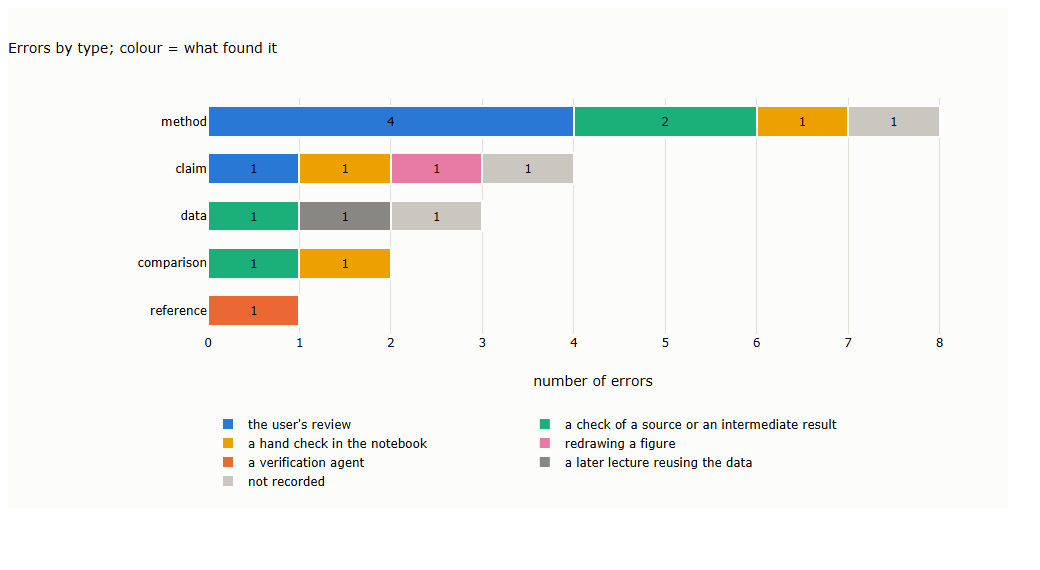

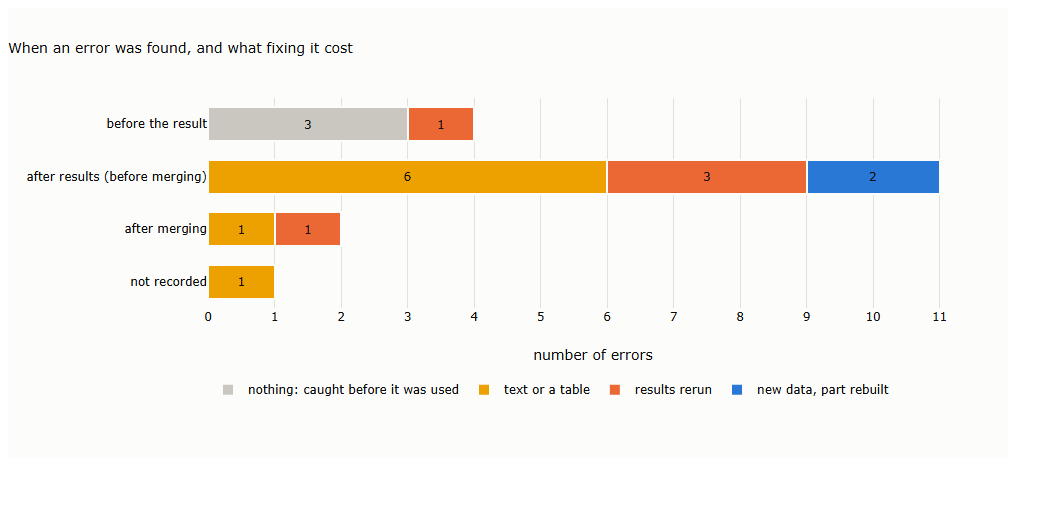

In [4]:
import plotly.io as pio
A.apply_theme()
A.FIG = pathlib.Path('nb_figures').resolve()
A.stacked(df, ('type', A.TYPES), 'found_by', {k: v[1] for k, v in A.FOUND.items()}, {k: v[0] for k, v in A.FOUND.items()},
          'Errors by type; colour = what found it', 'number of errors', '17_key_nb', 500)
A.stacked(df, ('stage', A.STAGES), 'cost_class', A.COST_COL, {k: k for k in A.COST_COL},
          'When an error was found, and what fixing it cost', 'number of errors', '17_stage_nb', 450)
from IPython.display import Image, display
for f in ['17_key_nb.png', '17_stage_nb.png']:
    p = A.FIG / f
    if p.exists(): display(Image(str(p)))

## Exercise 3: reclassify

Change the `type` or `found_by` of any row you judge differently and rerun the cells above. Do the readings of §6.2 change?